In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive, files
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [ ]:
drive.mount("/content/drive")
CARPETA_DRIVE = Path("/content/drive/MyDrive/ModelLOA/Datos_Procesados")
ARCHIVO_DATOS = CARPETA_DRIVE / "dataset_homicidios_final.csv"

df_homicidios = pd.read_csv(
    ARCHIVO_DATOS,
    engine="python",
    sep=None,
    encoding="utf-8-sig",
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Convertir fecha
df_homicidios["fecha"] = pd.to_datetime(df_homicidios["fecha"], dayfirst=True)

# Variables predictoras
columnas = [
    "codigo_provincia",
    "codigo_distrito",
    "franja_horaria",
    "es_feriado",
    "anio",
    "mes",
    "dia_semana_num"
]

X = df_homicidios[columnas]
y = df_homicidios["categoria_incidencia"]

In [ ]:
X = pd.get_dummies(
    X,
    columns=[
        "codigo_provincia",
        "codigo_distrito",
        "franja_horaria"
    ],
    dtype="int8"
)

In [ ]:
fecha_corte = df_homicidios['fecha'].quantile(0.8)
train_mask = df_homicidios['fecha'] < fecha_corte
test_mask = df_homicidios['fecha'] >= fecha_corte
X_train = X.loc[train_mask]
y_train = y.loc[train_mask]
X_test = X.loc[test_mask]
y_test = y.loc[test_mask]
print("Fecha de corte: ",fecha_corte)
print("Entrenamiento: ",X_train.shape)
print("Prueba: ",X_test.shape)


Fecha de corte:  2024-02-18 00:00:00
Entrenamiento:  (2072000, 172)
Prueba:  (518560, 172)


Debido al tamaño del conjunto de entrenamiento y a las limitaciones de memoria del entorno Google Colab, para el entrenamiento del modelo SVM se utilizó una muestra estratificada de 300,000 observaciones del conjunto de entrenamiento. La estratificación permitió conservar la distribución de las categorías de incidencia.

In [ ]:
from sklearn.model_selection import train_test_split

X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train,
    y_train,
    train_size=300000,
    stratify=y_train,
    random_state=42
)

print(y_train_sample.value_counts())
print(y_train_sample.value_counts(normalize=True))

categoria_incidencia
baja     297095
media      2529
alta        376
Name: count, dtype: int64
categoria_incidencia
baja     0.990317
media    0.008430
alta     0.001253
Name: proportion, dtype: float64


In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_sample)
X_test_scaled = scaler.transform(X_test)

In [ ]:
modelo_svm = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=42,
    max_iter=5000
)

modelo_svm.fit(X_train_scaled, y_train_sample)

LinearSVC(class_weight='balanced', max_iter=5000, random_state=42)

In [ ]:
y_pred = modelo_svm.predict(X_test_scaled)

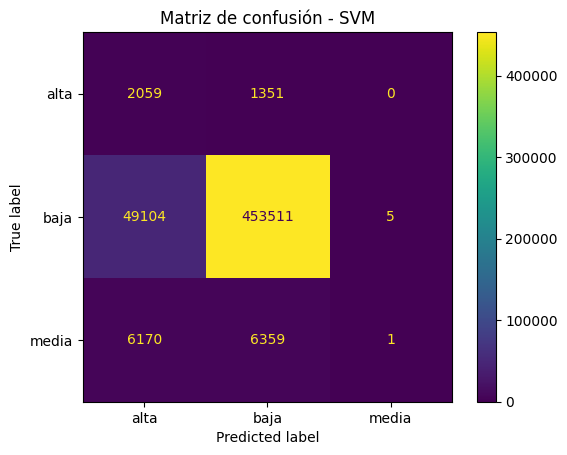

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=modelo_svm.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=modelo_svm.classes_
)

disp.plot()
plt.title("Matriz de confusión - SVM")
plt.show()

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print("RESULTADOS - SVM")
print("----------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

RESULTADOS - SVM
----------------------------
Accuracy:  0.8785
Precision: 0.9573
Recall:    0.8785
F1-Score:  0.9126


In [ ]:
print("REPORTE POR CLASE")
print("----------------------------")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

REPORTE POR CLASE
----------------------------
              precision    recall  f1-score   support

        alta       0.04      0.60      0.07      3410
        baja       0.98      0.90      0.94    502620
       media       0.17      0.00      0.00     12530

    accuracy                           0.88    518560
   macro avg       0.40      0.50      0.34    518560
weighted avg       0.96      0.88      0.91    518560

